<a href="https://colab.research.google.com/github/sripol/predictive_maintenance/blob/main/train_test_split.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###Business Context:
Vehicle breakdowns and engine failures lead to significant financial losses for both individual owners and fleet operators. Unexpected engine failures can cause expensive repairs, operational downtime, and safety risks. Predictive maintenance in the automotive industry can help minimize these issues by leveraging sensor data to forecast potential failures before they occur.

Automobile manufacturers, fleet managers, and service providers aim to develop data-driven solutions to improve engine reliability and optimize maintenance schedules. By analyzing engine health parameters such as RPM, temperature, pressure, and other sensor readings, machine learning models can be trained to predict when an engine requires maintenance, allowing proactive intervention before a failure occurs.

The sensor values in the dataset are consistent with the operating parameters of larger and small engines commonly found in equipment like Vechiles, lawnmowers, portable generators, and compact machinery. Some engines operate at lower RPMs, pressures, and temperatures compared to larger automotive engines and vice versa. Therefore, the data is appropriate for developing predictive maintenance models tailored to large and small engine applications.

###Objective:
As a Data Scientist, your goal is to build a predictive maintenance model that can analyze historical and real-time engine sensor data to identify potential failures. The model should accurately classify whether an engine requires maintenance or is operating normally.

This solution will help:

Reduce unplanned breakdowns and costly repairs.
Improve vehicle performance and engine lifespan.
Optimize maintenance schedules to minimize downtime
Provide data-driven insights to manufacturers and fleet operators for better decision-making.
Approach:
To achieve this objective, you will:

Explore and preprocess the dataset, handling missing values, outliers, and sensor anomalies.
Perform exploratory data analysis (EDA) to identify patterns in engine health parameters.
Develop machine learning models (e.g., Decision Trees, Random Forest, XGBoost, or Deep Learning models) to predict engine failures.
Evaluate model performance using appropriate classification metrics such as accuracy, precision, recall, and F1-score.
Deploy the model in a real-time monitoring system to alert users about potential failures.
By implementing a robust predictive maintenance system, this solution can lead to significant cost savings and improved efficiency in the automotive sector.

##Data Description:
####Engine_RPM: The number of revolutions per minute (RPM) of the engine, indicating engine speed. It is defined in Revolutions per Minute (RPM).
####Lub_Oil_Pressure: The pressure of the lubricating oil in the engine, essential for reducing friction and wear. It is defined in bar or kilopascals (kPa)
####Fuel_Pressure: The pressure at which fuel is supplied to the engine, critical for proper combustion. It is defined in bar or kilopascals (kPa)
####Coolant_Pressure: The pressure of the engine coolant, affecting engine temperature regulation. It is defined in bar or kilopascals (kPa)
#### Lub_Oil_Temperature: The temperature of the lubricating oil, which impacts viscosity and engine performance. It is defined in degrees Celsius (°C)
#### Coolant_Temperature: The temperature of the engine coolant, crucial for preventing overheating. It is defined in degrees Celsius (°C)
#### Engine_Condition: A categorical or numerical label representing the health of the engine, potentially indicating normal operation or various levels of wear and failure risks. It is defined as a categorical variable (0/1) representing a state such as "0 = Off/False/Active" and "1 = On/True/Faulty"

#Data Registration

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as sts
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import pickle

In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Loading and exploring the data.

In [ ]:
#DATA_PATH =  '/content/drive/MyDrive/Capstone_project_Predictive_Maintenance/data/'
#ARTIFACTS_PATH =  '/content/drive/MyDrive/Capstone_project_Predictive_Maintenance/artifacts/'
#df = pd.read_csv(f'{DATA_PATH}/engine_data.csv')

In [ ]:
DATA_PATH = 'data/'
ARTIFACTS_PATH = 'artifacts/'
df = pd.read_csv(f'{DATA_PATH}/engine_data.csv')

In [ ]:
Expected_columns = ["Engine rpm",	"Lub oil pressure",	"Fuel pressure",	"Coolant pressure", "lub oil temp", "Coolant temp",	"Engine Condition"]
for col in df.columns:
  if col not in Expected_columns:
    print(f"Column {col} is not expected")
    df.drop(col, axis=1, inplace=True)

In [ ]:
df.head()

,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition
0,700,2.493592,11.790927,3.178981,84.144163,81.632187,1
1,876,2.941606,16.193866,2.464504,77.640934,82.445724,0
2,520,2.961746,6.553147,1.064347,77.752266,79.645777,1
3,473,3.707835,19.510172,3.727455,74.129907,71.774629,1
4,619,5.672919,15.738871,2.052251,78.396989,87.000225,0


In [ ]:
df.shape

(19535, 7)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19535 entries, 0 to 19534
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Engine rpm        19535 non-null  int64  
 1   Lub oil pressure  19535 non-null  float64
 2   Fuel pressure     19535 non-null  float64
 3   Coolant pressure  19535 non-null  float64
 4   lub oil temp      19535 non-null  float64
 5   Coolant temp      19535 non-null  float64
 6   Engine Condition  19535 non-null  int64  
dtypes: float64(5), int64(2)
memory usage: 1.0 MB


In [ ]:
df.describe()

,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition
count,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000,19535.000000
mean,791.239263,3.303775,6.655615,2.335369,77.643420,78.427433,0.630509
std,267.611193,1.021643,2.761021,1.036382,3.110984,6.206749,0.482679
min,61.000000,0.003384,0.003187,0.002483,71.321974,61.673325,0.000000
25%,593.000000,2.518815,4.916886,1.600466,75.725990,73.895421,0.000000
50%,746.000000,3.162035,6.201720,2.166883,76.817350,78.346662,1.000000
75%,934.000000,4.055272,7.744973,2.848840,78.071691,82.915411,1.000000
max,2239.000000,7.265566,21.138326,7.478505,89.580796,195.527912,1.000000


## Data is loaded from CSV file into a data frame.
#### Data has 7 columns and 19535 rows.
#### All the features are numerical.
#### Engine rpm and Engine Condition are of type Int64. Specifically Engine condition is categorical (1- Good or 0 - Bad).
#### Rest of the features (Lub oil pressure, Fuel pressure, cooland pressure, lub oil temp and oolant temp) are contineous variables.

## Interquartile range
##### Engine RPM - 593 to 934
##### Lub Oil pressure - 2.518815 to 4.055272
##### Fuel Pressure - 4.92 to 7.75
##### Coolant pressure - 1.6 to 2.85
##### lub oil temp - 75.73 to 78
##### Coolant temp - 73.90 to 82.92


## Univariate analysis

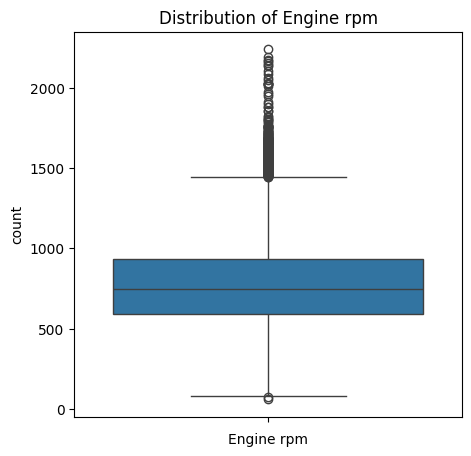

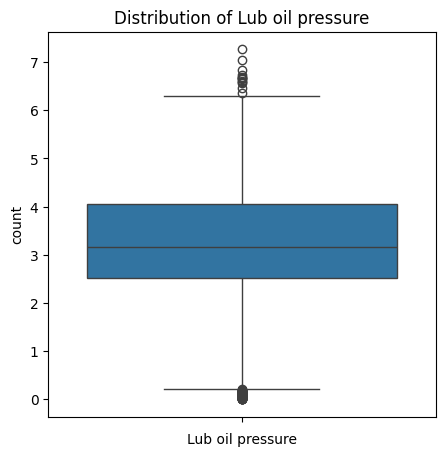

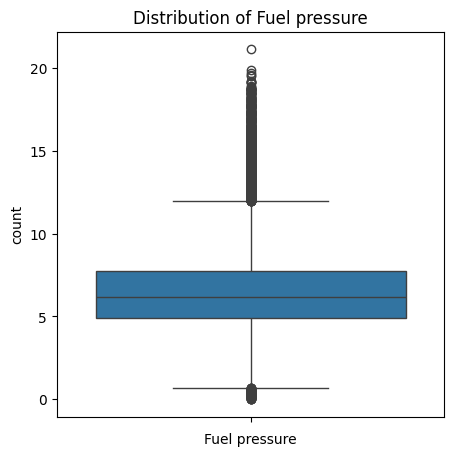

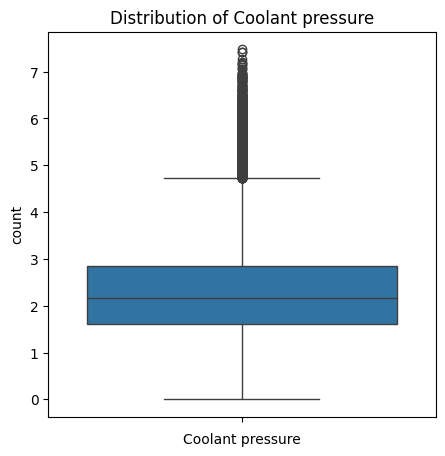

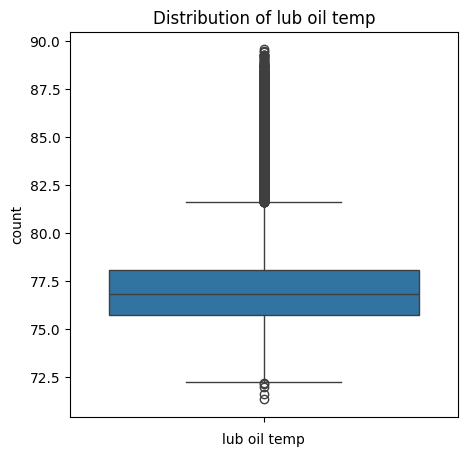

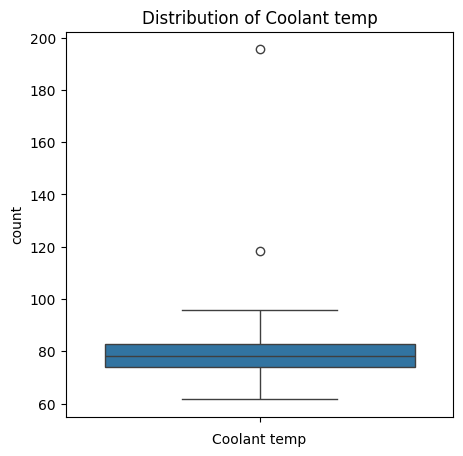

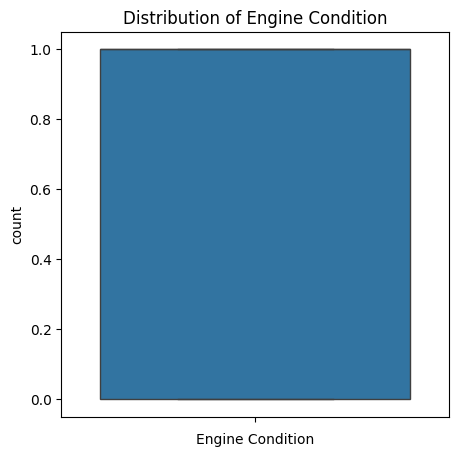

In [ ]:
for col in df.columns:
  plt.figure(figsize=(5,5))
  sns.boxplot(df[col], orient = 'v')
  plt.title(f'Distribution of {col}')
  plt.xlabel(f'{col}')
  plt.ylabel('count')
  plt.show()
  print("\n")

#### Most of the engines have 500 to 1000 RPM. But there are significant number of engines with above 1500 RPM and a few below 100 RPM.
#### Lube oil pressure is between 2.5 to 4. There are some engines with pressure close to 0 and some above 12.
#### Mostly the Fuel pressure is between 5 to 7. Significant numbers above 12 and some close to 0.
#### Coolant pressure is mostly 1.5 to 3. Significant number of engines have above 4.5.
#### Lub oil temperature is between 76 to 78. Significant number of engines have the temperatures higher than 82.5. Some of them are much lower at 72.5 or less.
#### Coolant temperature typically is between 75 to 85. There are some outliers at 120 and 200.


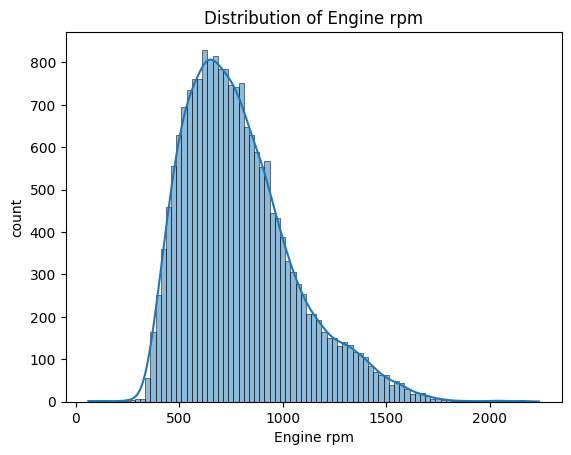

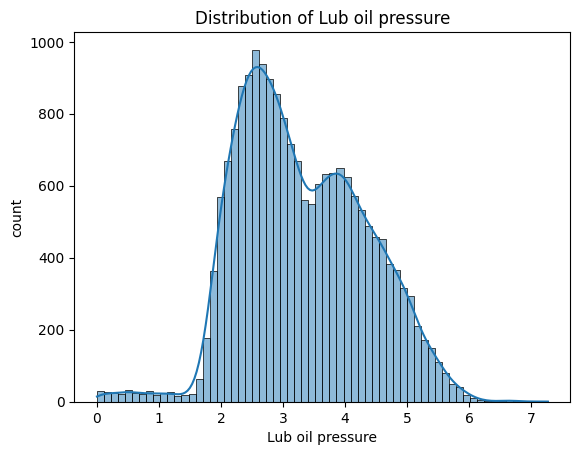

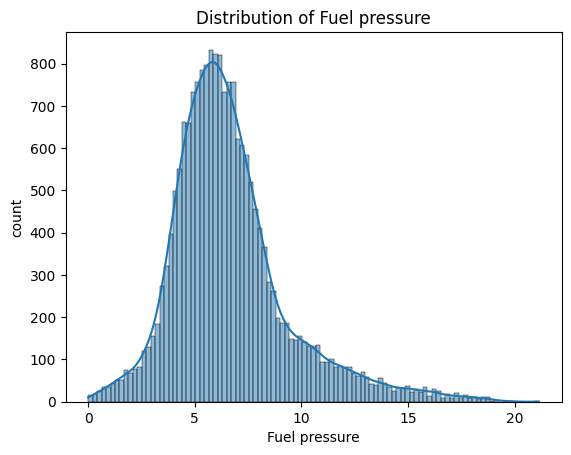

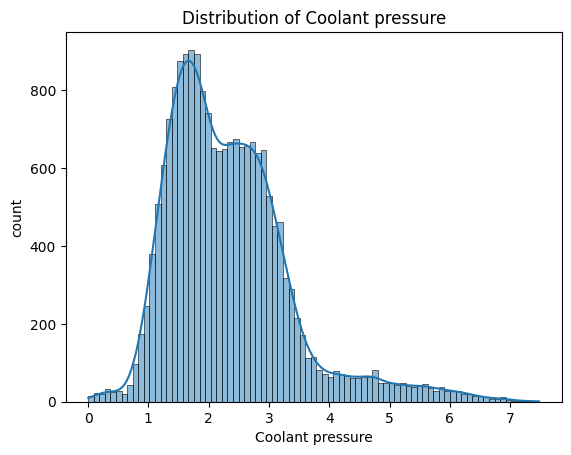

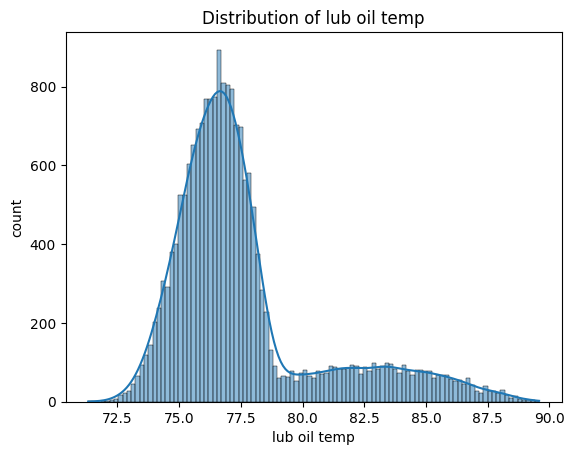

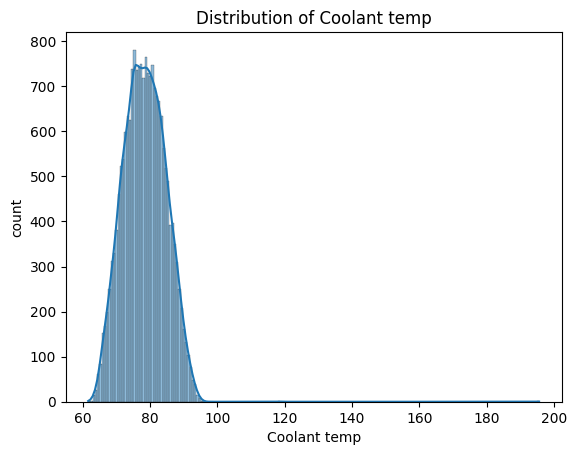

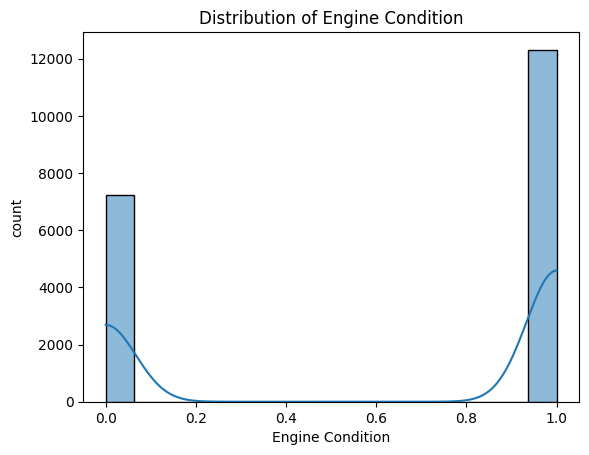

In [ ]:
for col in df.columns:
  sns.histplot(df[col], kde=True)
  plt.title(f'Distribution of {col}')
  plt.xlabel(f'{col}')
  plt.ylabel('count')
  plt.show()

### Data is imbalanced.
### Around 7000 vehicles are with Bad condition.  
### Around 12000 vehicles are with Good condition.

### Bivariate analysis

#### Plot showing the median, quartiles and outliers for both the Engine conditions separately for each of the features.

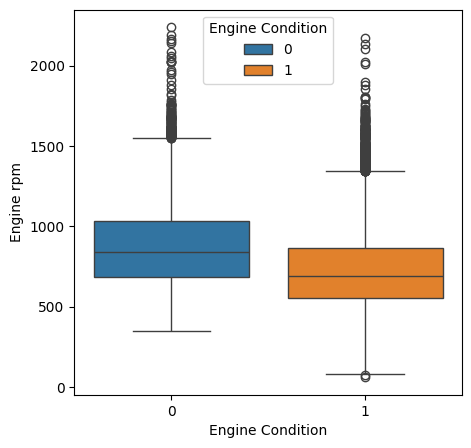

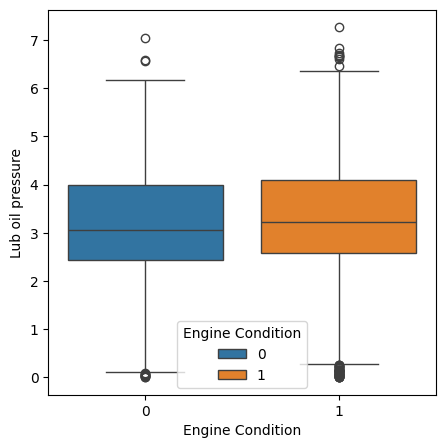

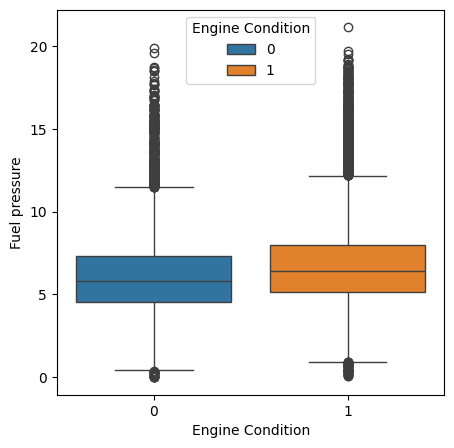

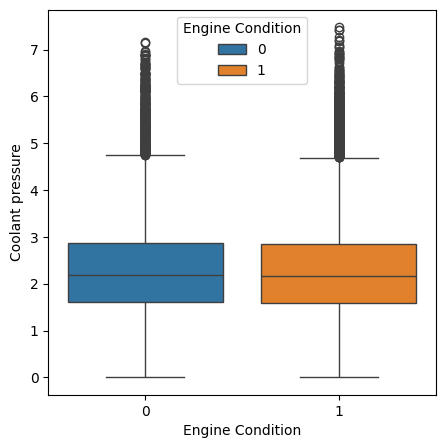

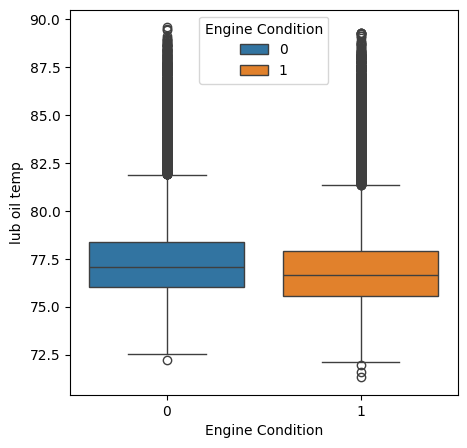

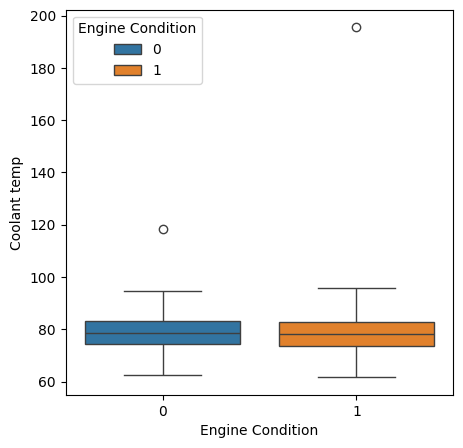

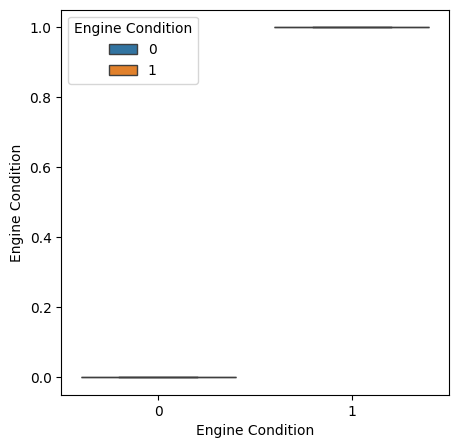

In [ ]:
for col in df.columns:
  plt.figure(figsize=(5,5))
  sns.boxplot(data=df, y = col, x='Engine Condition' ,hue='Engine Condition', orient='v')
  plt.show()
  print("\n")

#### Histogram distribution of features for both the engine conditions.

<Figure size 500x500 with 0 Axes>

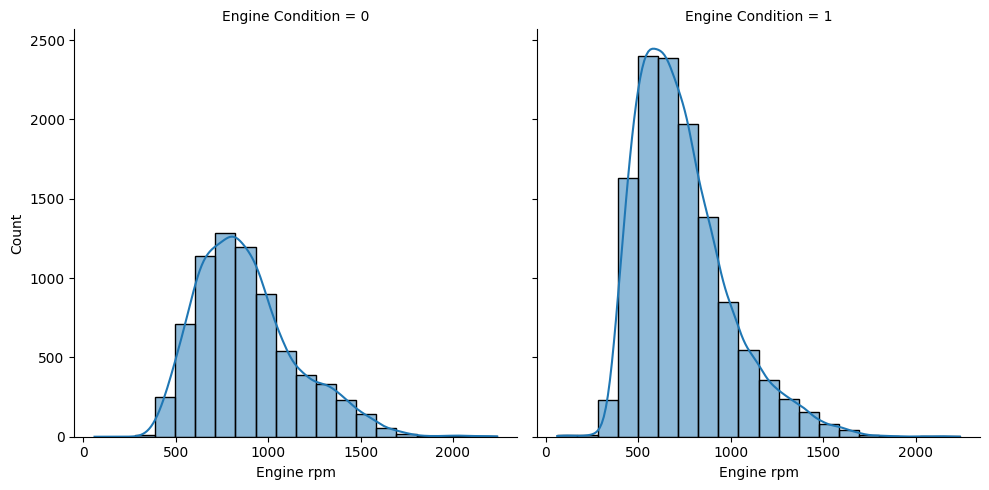

<Figure size 500x500 with 0 Axes>

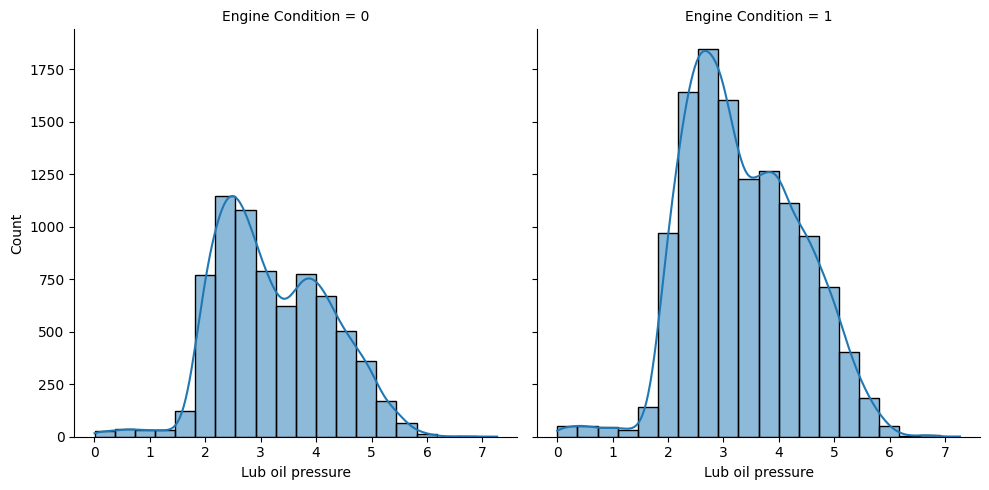

<Figure size 500x500 with 0 Axes>

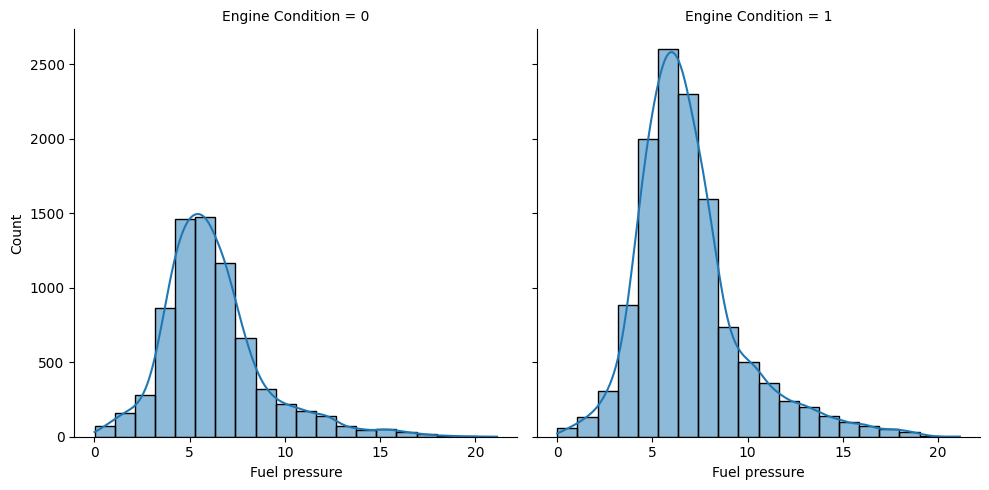

<Figure size 500x500 with 0 Axes>

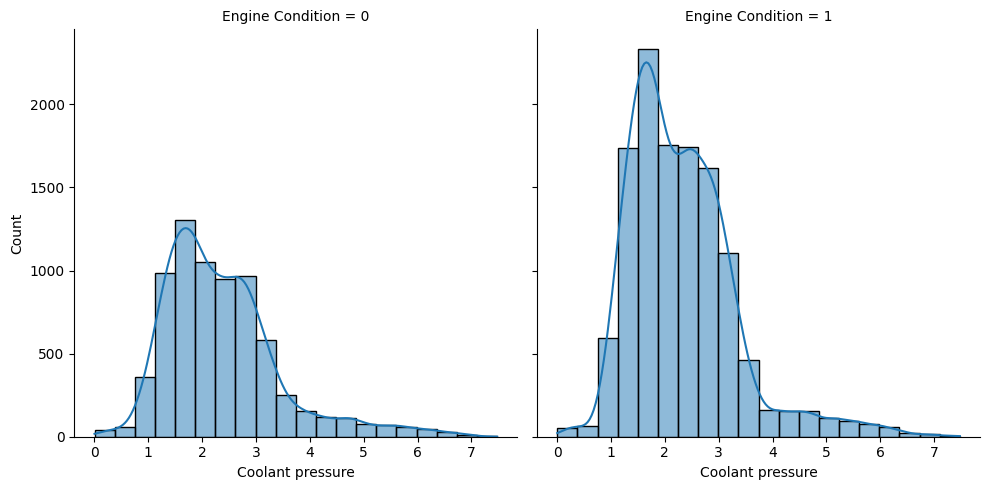

<Figure size 500x500 with 0 Axes>

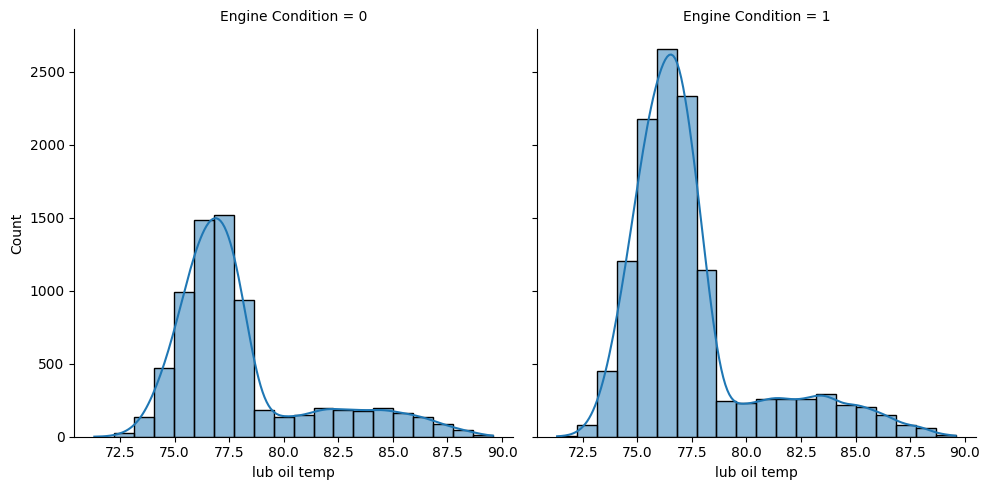

<Figure size 500x500 with 0 Axes>

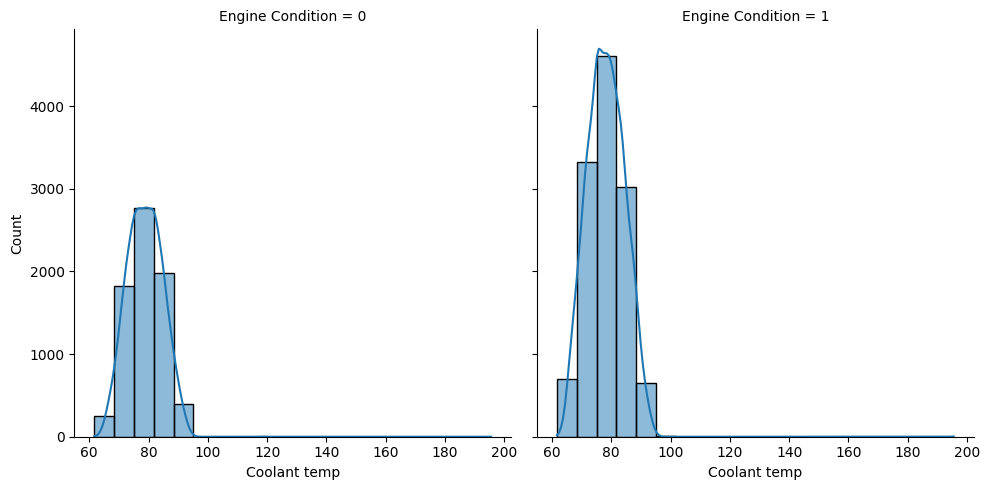

<Figure size 500x500 with 0 Axes>

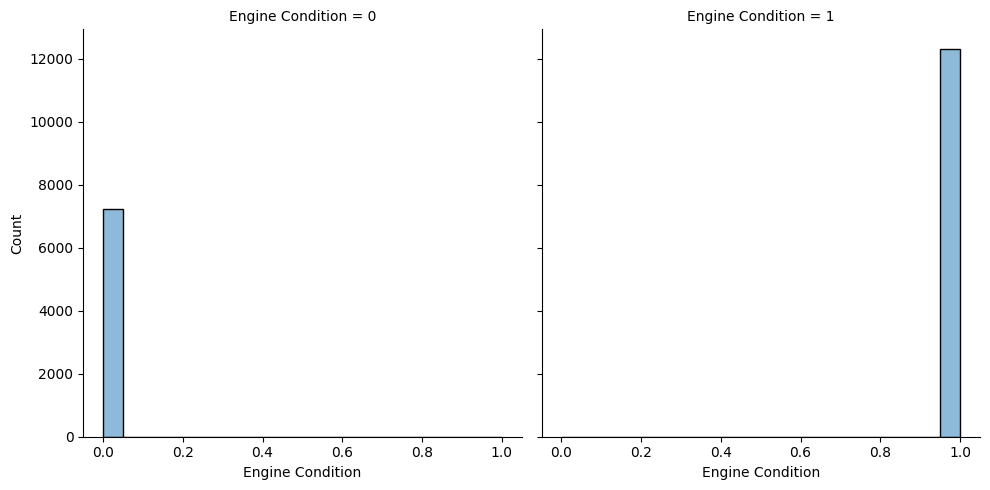

In [ ]:
for col in df.columns:
  plt.figure(figsize=(5,5))
  sns.displot(data=df, x=col, col="Engine Condition", bins=20, kde=True)
  plt.show()
  print("\n")

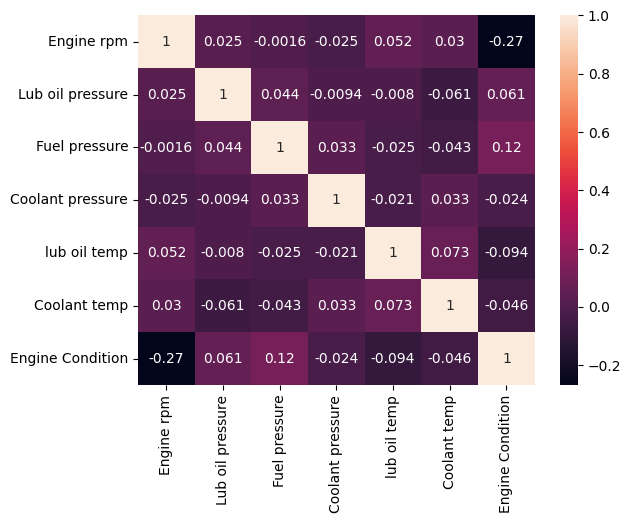

In [ ]:
sns.heatmap(df.corr(), annot=True)
plt.show()

### Correlation can't be performed for categorical variables.  Also, there is almost no correlation between other contineous variables.

### Data preperation

In [ ]:
df.shape

(19535, 7)

In [ ]:
df.dropna(inplace=True)

In [ ]:
df.shape

(19535, 7)

In [ ]:
df.isnull().sum()

,0
Engine rpm,0
Lub oil pressure,0
Fuel pressure,0
Coolant pressure,0
lub oil temp,0
Coolant temp,0
Engine Condition,0


In [ ]:
df.shape

(19535, 7)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.shape

(19535, 7)

In [ ]:
for col in df.columns:
  z_scores = np.abs(sts.zscore(df[col]))
outliers = df[z_scores > 3]
print(f"outliers {outliers}")

outliers Empty DataFrame
Columns: [Engine rpm, Lub oil pressure, Fuel pressure, Coolant pressure, lub oil temp, Coolant temp, Engine Condition]
Index: []


### There are no null or invalid values in the data.
### There are no outliers in the data.

### Normalize the values so that each feature bears equal weight irrespective of the range or scale.

In [ ]:
scaler = MinMaxScaler()
for col in df.columns:
  if col != 'Engine Condition':
    df[[col]] = scaler.fit_transform(df[[col]])

df.head()

,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition
0,0.293388,0.342901,0.557732,0.424891,0.702246,0.149109,1
1,0.374197,0.404592,0.766055,0.329322,0.346077,0.155186,0
2,0.210744,0.407365,0.309909,0.142036,0.352175,0.134268,1
3,0.189164,0.510102,0.922965,0.498256,0.153785,0.075465,1
4,0.256198,0.780693,0.744527,0.274179,0.387485,0.189212,0


### Split the data in train and test

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(df.drop('Engine Condition', axis=1), df['Engine Condition'], test_size=0.2, random_state=42)

In [ ]:
x_train.head()

,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp
6690,489,2.134818,5.674162,3.370571,76.291865,74.695573
1255,910,2.105410,5.381185,1.714422,75.479919,79.927530
3315,523,2.991344,4.781397,2.687113,76.939586,76.401910
3684,727,2.928145,8.276127,1.318319,78.202955,71.288606
10223,666,3.527191,8.625874,2.096356,74.028029,66.678025


In [ ]:
y_train.head()

,Engine Condition
6690,1
1255,0
3315,0
3684,1
10223,1


### Save the split data as pickle file in the google drive path to let them get picked in the next module in the pipeline.

In [ ]:
open(f"{ARTIFACTS_PATH}/x_train.pkl", "wb").write(pickle.dumps(x_train))
open(f"{ARTIFACTS_PATH}/x_test.pkl", "wb").write(pickle.dumps(x_test))
open(f"{ARTIFACTS_PATH}/y_train.pkl", "wb").write(pickle.dumps(y_train))
open(f"{ARTIFACTS_PATH}/y_test.pkl", "wb").write(pickle.dumps(y_test))

94414